In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

channels = ['Google Ads', 'Meta Ads', 'Email Marketing', 'Influencer', 'Organic Search']
n_campaigns = 50

data = []
for i in range(n_campaigns):
    channel = np.random.choice(channels)
    spend = np.random.randint(1000, 20000)
    impressions = int(spend * np.random.uniform(20, 50))
    clicks = int(impressions * np.random.uniform(0.01, 0.05))
    acquisitions = int(clicks * np.random.uniform(0.02, 0.10))
    revenue = acquisitions * np.random.uniform(100, 350)
    
    data.append({
        'CampaignID': f'CMP-{1000+i}',
        'Channel': channel,
        'Spend': spend,
        'Impressions': impressions,
        'Clicks': clicks,
        'Acquisitions': acquisitions,
        'Revenue': round(revenue, 2)
    })

df_mkt = pd.DataFrame(data)


df_mkt['CTR (%)'] = (df_mkt['Clicks'] / df_mkt['Impressions']) * 100
df_mkt['CAC ($)'] = np.where(df_mkt['Acquisitions'] > 0, df_mkt['Spend'] / df_mkt['Acquisitions'], np.nan)
df_mkt['ROI (%)'] = ((df_mkt['Revenue'] - df_mkt['Spend']) / df_mkt['Spend']) * 100


channel_summary = df_mkt.groupby('Channel').agg(
    Total_Spend=('Spend', 'sum'),
    Total_Revenue=('Revenue', 'sum'),
    Total_Acquisitions=('Acquisitions', 'sum'),
    Avg_CTR=('CTR (%)', 'mean'),
    Avg_CAC=('CAC ($)', 'mean')
).reset_index()

channel_summary['Overall_ROI (%)'] = ((channel_summary['Total_Revenue'] - channel_summary['Total_Spend']) / channel_summary['Total_Spend']) * 100

print("=== 📊 خلاصه عملکرد کانال‌های بازاریابی ===")
print(channel_summary.round(2).sort_values(by='Overall_ROI (%)', ascending=False).to_string(index=False))

=== 📊 خلاصه عملکرد کانال‌های بازاریابی ===
        Channel  Total_Spend  Total_Revenue  Total_Acquisitions  Avg_CTR  Avg_CAC  Overall_ROI (%)
     Google Ads       100739     2338705.45                9041     3.17    26.39          2221.55
       Meta Ads       102808     2016850.96                9284     3.36    19.68          1861.76
 Organic Search        67046     1070768.15                4494     2.82    31.20          1497.06
     Influencer       126811     1545625.84                7142     2.57    29.59          1118.84
Email Marketing       116625     1048718.55                6217     3.17    25.29           799.22


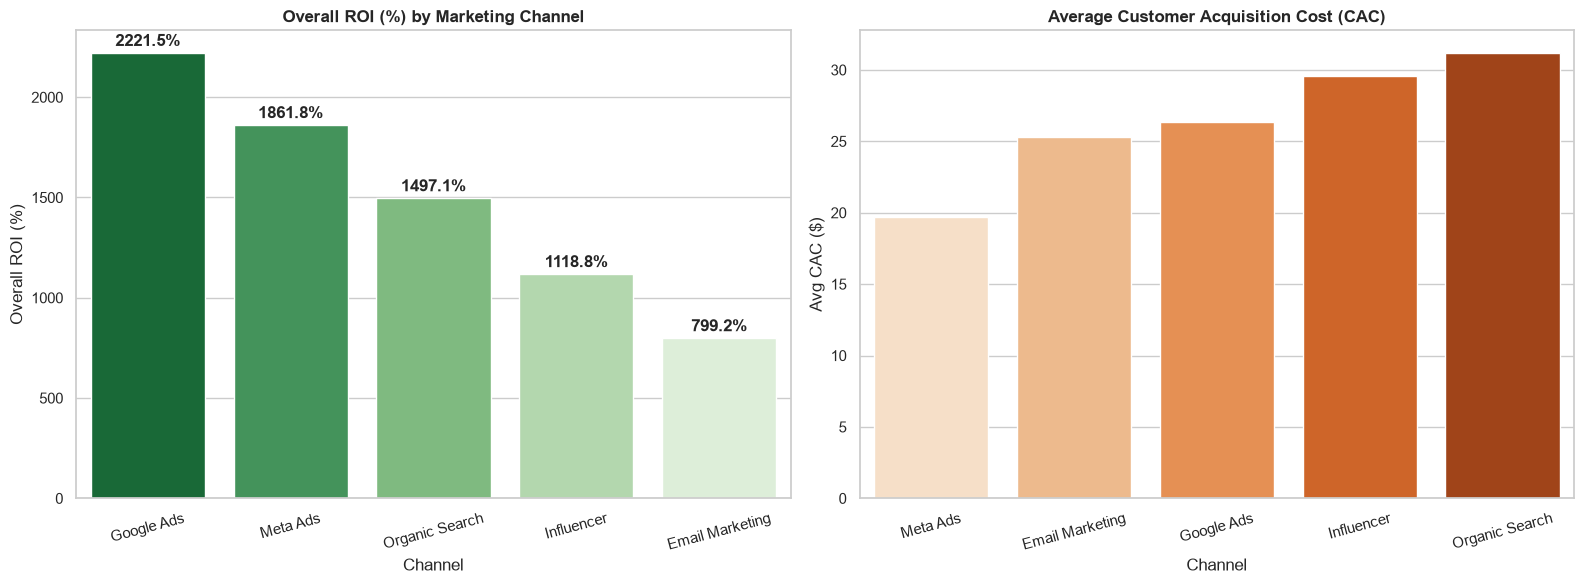

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))


sns.barplot(
    ax=axes[0], 
    data=channel_summary.sort_values(by='Overall_ROI (%)', ascending=False), 
    x='Channel', 
    y='Overall_ROI (%)', 
    hue='Channel', 
    palette='Greens_r', 
    legend=False
)
axes[0].set_title('Overall ROI (%) by Marketing Channel', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Channel')
axes[0].set_ylabel('Overall ROI (%)')
axes[0].tick_params(axis='x', rotation=15)


for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.1f}%', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', 
                    xytext=(0, 8), 
                    textcoords='offset points', 
                    fontweight='bold')


sns.barplot(
    ax=axes[1], 
    data=channel_summary.sort_values(by='Avg_CAC'), 
    x='Channel', 
    y='Avg_CAC', 
    hue='Channel', 
    palette='Oranges', 
    legend=False
)
axes[1].set_title('Average Customer Acquisition Cost (CAC)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Channel')
axes[1].set_ylabel('Avg CAC ($)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()